# 4. What drives the predictions

**Life Expectancy Predictor · notebook 4 of 7**

A model that is accurate but unexplainable is hard to trust. This notebook opens the random forest up and asks two questions: *which* inputs it leans on, and *how* each one pushes the prediction up or down. Both answers should agree with what public-health experts already know; if they didn't, that would be a warning sign that the model had found a shortcut in the data rather than something real.

## Step 1: Which inputs matter most (permutation importance)

**What we are looking for.** A ranking of the 13 inputs by how much the model needs each one.

The method is simple to describe: take the trained model and the held-out rows, scramble one column so it becomes noise, and measure how much worse the predictions get. An input the model relies on causes a big drop when scrambled; an input it ignores causes none. Repeat for every column. This is called *permutation importance*.

Project folder: nb


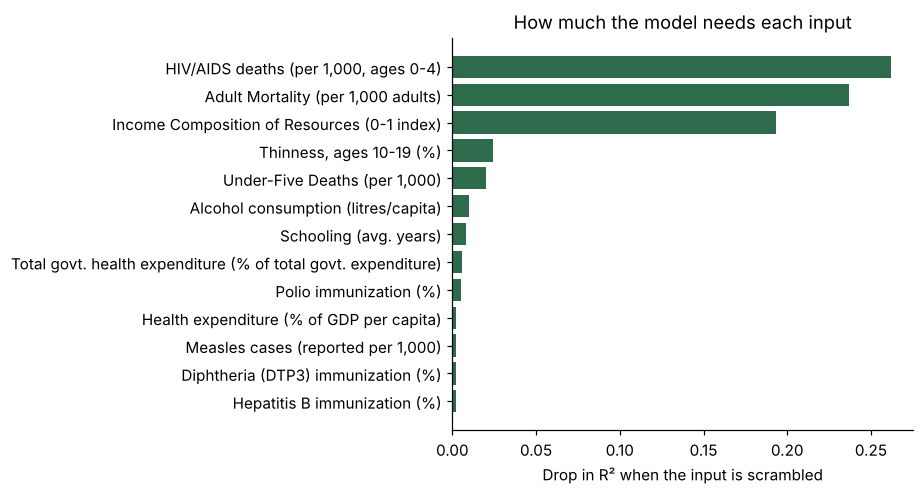

,Input,Drop in R² when scrambled
0,"HIV/AIDS deaths (per 1,000, ages 0-4)",0.262
1,"Adult Mortality (per 1,000 adults)",0.237
2,Income Composition of Resources (0-1 index),0.193
3,"Thinness, ages 10-19 (%)",0.024
4,"Under-Five Deaths (per 1,000)",0.020
5,Alcohol consumption (litres/capita),0.010
6,Schooling (avg. years),0.008
7,Total govt. health expenditure (% of total gov...,0.006
8,Polio immunization (%),0.005
9,Health expenditure (% of GDP per capita),0.002


In [1]:
# Setup: find the project folder and load the project's own code and settings.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config_loader import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config = load_config(str(ROOT / "config" / "who_life_expectancy.yaml"), base_dir=str(ROOT))

def results(name):
    """Load one of the saved results files in model/."""
    return json.loads((ROOT / "model" / f"{name}.json").read_text(encoding="utf-8"))

print("Project folder:", ROOT.name)
from data_prep import get_unclipped_df
from train_model import rf_pipeline
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance

df = get_unclipped_df(config)
X = df[config.predictor_columns].to_numpy(); y = df[config.target_column].to_numpy()
mp = config.model_params
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=mp["test_size"], random_state=mp["random_state"])
model = rf_pipeline(config, n_estimators=mp["n_estimators"], random_state=mp["random_state"], n_jobs=-1).fit(X_tr, y_tr)

labels = {p.column: p.label for p in config.predictors}
pi = permutation_importance(model, X_te, y_te, n_repeats=10, random_state=0, n_jobs=-1)
imp = pd.DataFrame({"Input": [labels[c] for c in config.predictor_columns],
                    "Drop in R² when scrambled": pi.importances_mean.round(3)}).sort_values("Drop in R² when scrambled")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh(imp["Input"], imp["Drop in R² when scrambled"], color="#2E6A4C")
ax.set(title="How much the model needs each input", xlabel="Drop in R² when the input is scrambled")
plt.tight_layout(); plt.show()
imp.iloc[::-1].reset_index(drop=True)

**How to read it.** Longer bar = more important. The number is how much R² falls when that input is replaced with noise.

**What it means.** Three inputs do almost all the work: **HIV/AIDS deaths, adult mortality, and the income-composition index** (a UN measure of how well a country turns its income into living standards). Scrambling any one of them costs the model 0.2-0.26 of its R²; scrambling any of the other ten costs 0.02 or less. The immunization rates, health spending and measles barely register.

This matches what is known about the period. HIV/AIDS was the single biggest driver of the very low life expectancies seen in parts of sub-Saharan Africa around 2000-2010; adult mortality is almost a direct reading of the same thing; and the income index captures the broad development gap. The model is reading the big, true signals, not an artefact.

A caution: "unimportant" here means *the model doesn't need it*, not *it doesn't matter in reality*. Immunization rates are strongly linked to development, so once the income index is known they add little new information. Permutation importance measures redundancy as well as relevance.

**What's next and why.** Importance says *that* an input matters; the next step shows *in which direction, and how steeply*.

## Step 2: How each input moves the prediction (partial dependence)

**What we are looking for.** For each of the top three inputs: if you slid its value from low to high while holding everything else fixed, what would the predicted life expectancy do?

This is *partial dependence*. For each value on a grid, every row in the data is given that value for the one input, the model predicts all of them, and the predictions are averaged.

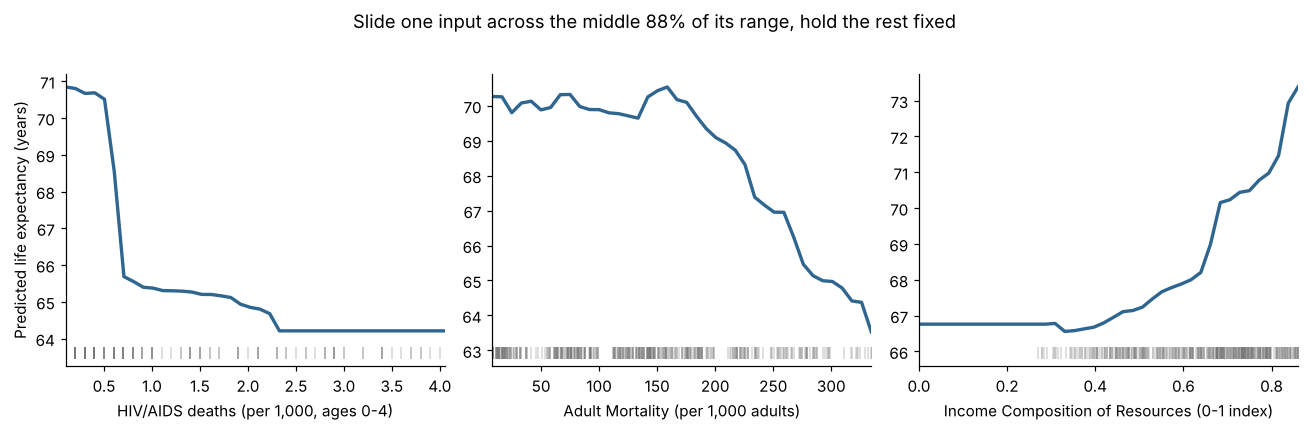

In [2]:
top3 = ["HIV_AIDS", "Adult_Mortality", "Income_Comp_Of_Resources"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, col in zip(axes, top3):
    j = config.predictor_columns.index(col)
    lo, hi = np.percentile(X_te[:, j], [2, 90])          # the middle 88% of the data
    grid = np.linspace(lo, hi, 40)
    avg = []
    for v in grid:                                      # set every row's value to v, predict, average
        X_mod = X_te.copy(); X_mod[:, j] = v
        avg.append(model.predict(X_mod).mean())
    ax.plot(grid, avg, color="#2F6690", lw=2.2)
    ax.plot(X_te[:, j], np.full(len(X_te), min(avg) - 0.6), "|", color="#777", alpha=0.3, ms=8)   # where the data sits
    ax.set(xlabel=labels[col], xlim=(lo, hi))
axes[0].set_ylabel("Predicted life expectancy (years)")
fig.suptitle("Slide one input across the middle 88% of its range, hold the rest fixed", y=1.02)
plt.tight_layout(); plt.show()

**How to read it.** Each panel: the input on the horizontal axis, the model's average prediction on the vertical. The range shown is the middle 88% of the data (the extreme 2% at the bottom and 10% at the top are left off, since the curve is not reliable where there are few rows). The small ticks along the bottom show where the real data sits.

**What it means.**

- **HIV/AIDS deaths:** the sharpest curve. Around 0.5 deaths per 1,000 (ages 0-4) there is a cliff: the prediction drops from about 71 to 66 years almost at once, then slides to about 64 by 2.3. Beyond that it is flat: that is the clipping limit from notebook 2 at work (values above the cut-off count as "very high", not ever higher). In plain terms, the model has learned that *any* serious HIV burden costs about five years, and more costs a little more.
- **Adult mortality:** flat up to about 150 deaths per 1,000 adults, then a steady slide of about 7 years by 330. Below 150 the model treats countries as "low mortality" and lets other inputs decide. No surprises; this is nearly a definition.
- **Income-composition index:** flat below about 0.35 (where there is little data), then rises by about 6.5 years up to 0.9: better-developed countries live longer, and the gain accelerates at the top.

All three curves slope in the direction a public-health expert would predict. The model has learned the real structure of the problem.

**What's next and why.** The model is accurate and sensible on average. Notebook 5 looks at where it is *not*: the specific countries it gets badly wrong, and why that cannot simply be patched.

## Summary

| Question | Answer |
| --- | --- |
| Which inputs matter? | HIV/AIDS deaths, adult mortality, income-composition index, by a wide margin |
| Which barely matter to the model? | Immunization rates, health spending, measles, alcohol, thinness (mostly redundant once the top three are known) |
| Do the directions make sense? | Yes: more HIV deaths or adult mortality → shorter lives; higher development → longer |
| Any sign of a shortcut? | No: the model's reasoning matches known public-health facts |